In [6]:
import pandas as pd
df = pd.read_csv('zomato.csv')
df = df.rename(columns={'approx_cost(for two people)': 'approx_cost'})
df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost,reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [7]:
df = df[df['rate'] != 'NEW']
df = df[df['rate'] != '-']
df['rate'] = df['rate'].apply(lambda x: float(str(x).split('/')[0]))
df['approx_cost'] = df['approx_cost'].astype(str).str.replace(',', '').astype(float)
df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost,reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800.0,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800.0,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800.0,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300.0,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600.0,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [8]:
print("Total Restaurants:", df.shape[0])
print("Average Rating:", round(df['rate'].mean(), 2))
print("Average Cost for 2:", round(df['approx_cost'].mean(), 2))
print("\nTop 5 Locations:")
print(df['location'].value_counts().head(5))
print("\nTop 10 Restaurants:")
top10 = df.sort_values(by=['rate', 'votes'], ascending=False).head(10)
top10[['name', 'rate', 'votes', 'location', 'cuisines', 'approx_cost']]

Total Restaurants: 49440
Average Rating: 3.7
Average Cost for 2: 561.22

Top 5 Locations:
location
BTM                      4793
Koramangala 5th Block    2442
HSR                      2414
JP Nagar                 2103
Whitefield               2033
Name: count, dtype: int64

Top 10 Restaurants:


,name,rate,votes,location,cuisines,approx_cost
49170,Byg Brewski Brewing Company,4.9,16832,Sarjapur Road,"Continental, North Indian, Italian, South Indi...",1600.0
49627,Byg Brewski Brewing Company,4.9,16832,Sarjapur Road,"Continental, North Indian, Italian, South Indi...",1600.0
50059,Byg Brewski Brewing Company,4.9,16832,Sarjapur Road,"Continental, North Indian, Italian, South Indi...",1600.0
3921,Byg Brewski Brewing Company,4.9,16345,Sarjapur Road,"Continental, North Indian, Italian, South Indi...",1600.0
4801,Byg Brewski Brewing Company,4.9,16345,Sarjapur Road,"Continental, North Indian, Italian, South Indi...",1600.0
4944,Byg Brewski Brewing Company,4.9,16345,Sarjapur Road,"Continental, North Indian, Italian, South Indi...",1600.0
37099,AB's - Absolute Barbecues,4.9,6490,BTM,"European, Mediterranean, North Indian, BBQ",1600.0
21279,AB's - Absolute Barbecues,4.9,6452,BTM,"European, Mediterranean, North Indian, BBQ",1600.0
19393,AB's - Absolute Barbecues,4.9,6404,BTM,"European, Mediterranean, North Indian, BBQ",1600.0
21770,AB's - Absolute Barbecues,4.9,6404,BTM,"European, Mediterranean, North Indian, BBQ",1600.0


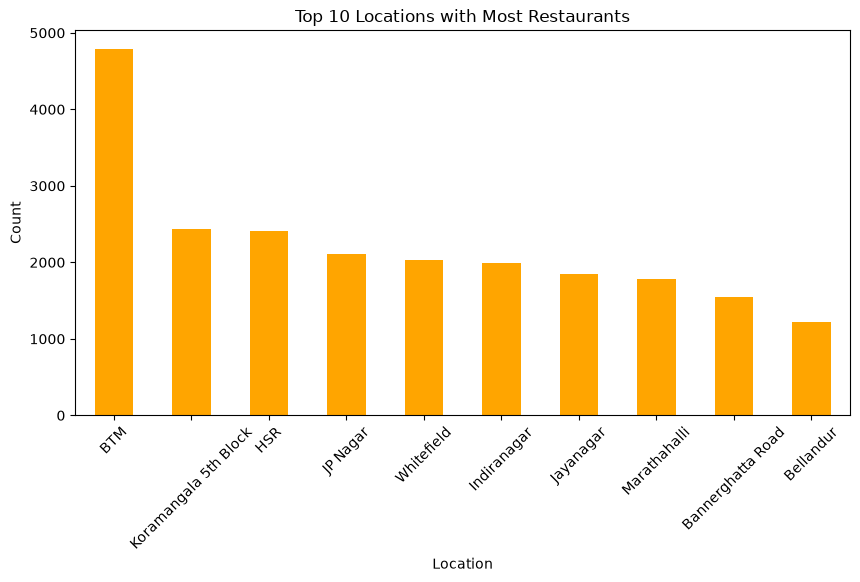

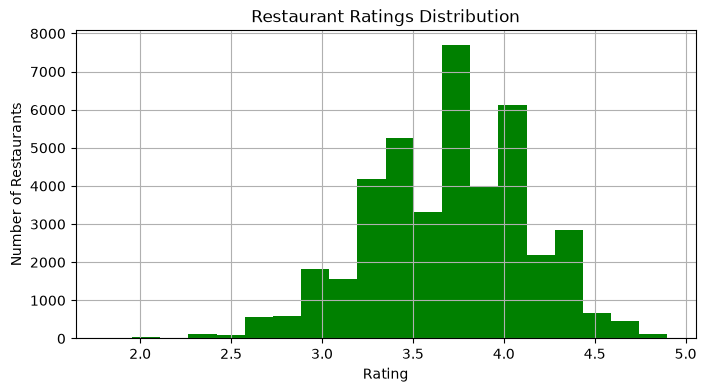

In [9]:
import matplotlib.pyplot as plt

# Graph 1 - Top 10 Locations
plt.figure(figsize=(10,5))
df['location'].value_counts().head(10).plot(kind='bar', color='orange')
plt.title('Top 10 Locations with Most Restaurants')
plt.xlabel('Location')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

# Graph 2 - Rating Distribution
plt.figure(figsize=(8,4))
df['rate'].hist(bins=20, color='green')
plt.title('Restaurant Ratings Distribution')
plt.xlabel('Rating')
plt.ylabel('Number of Restaurants')
plt.show()